## Progetto 1 Modulo 3

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import DBSCAN, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

## Data Exploration & Preprocessing

In [3]:
iris = load_iris()
X, y = iris.data, iris.target
feature_names = iris.feature_names
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [4]:
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

## Stima di K con DBSCAN

--- EPS = 0.35 ---
Cluster trovati (K): 4
Assegnati: 46 | Rumore (noise): 104 | Percentuale: 30.67%



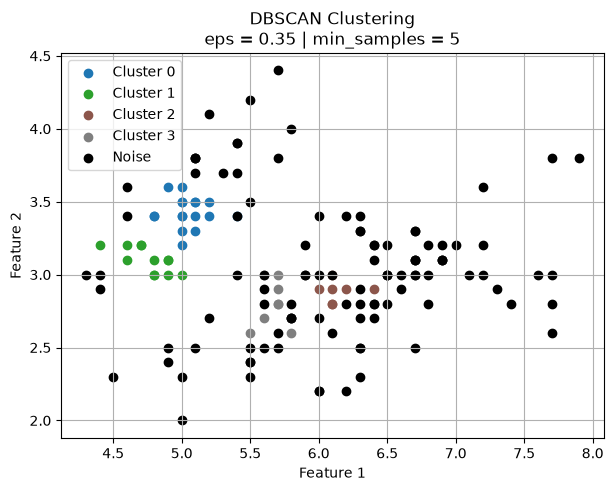

--- EPS = 0.45 ---
Cluster trovati (K): 3
Assegnati: 96 | Rumore (noise): 54 | Percentuale: 64.00%



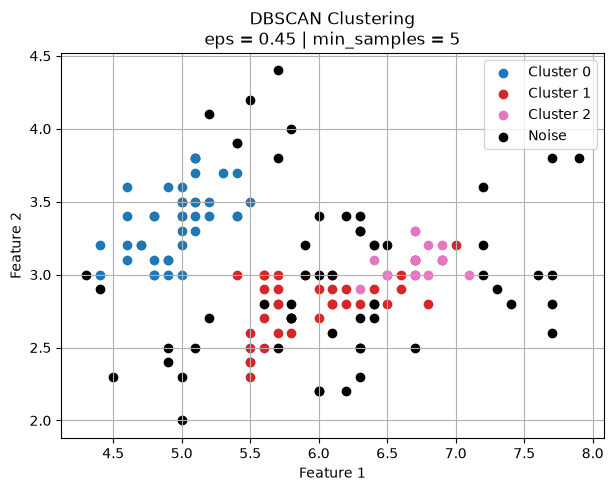

--- EPS = 0.55 ---
Cluster trovati (K): 2
Assegnati: 121 | Rumore (noise): 29 | Percentuale: 80.67%



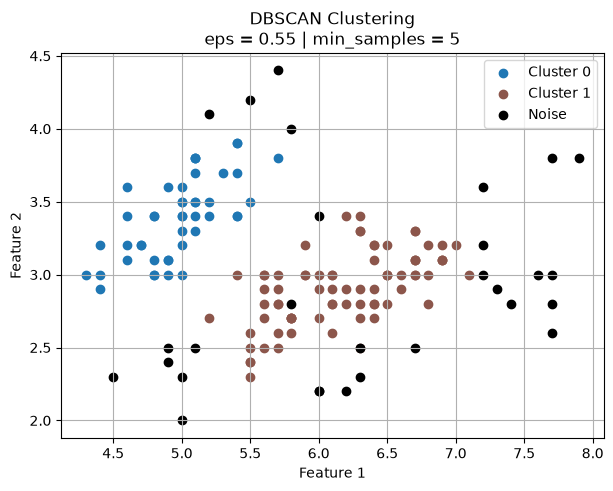

In [12]:
eps_values = [0.35, 0.45, 0.55]
min_samples = 5

for eps in eps_values:
  dbscan = DBSCAN(eps=eps, min_samples=min_samples)
  dbscan.fit(X_std)
  labels = dbscan.labels_


  n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
  tot = len(labels)
  noise = np.sum(labels == -1) 
  assigned = tot - noise
  pct_assigned = (assigned / tot) * 100

  print(f'--- EPS = {eps} ---')
  print(f'Cluster trovati (K): {n_clusters}')
  print(
      f'Assegnati: {assigned} | Rumore (noise): {noise} | Percentuale:'
      f' {pct_assigned:.2f}%\n'
  )

  
  plt.figure(figsize=(7, 5))
  unique_labels = set(labels)
  colors = [plt.cm.tab10(each) for each in np.linspace(0, 1, len(unique_labels))]

  for k, col in zip(unique_labels, colors):
    if k == -1:
      col = (0, 0, 0, 1)  
    class_member_mask = labels == k
    xy = X[class_member_mask]
    plt.scatter(
        xy[:, 0], xy[:, 1], c=[col], label=f'Cluster {k}' if k != -1 else 'Noise'
    )

  plt.xlabel('Feature 1')
  plt.ylabel('Feature 2')
  plt.title(f'DBSCAN Clustering\neps = {eps} | min_samples = {min_samples}')
  plt.legend()
  plt.grid(True)
  plt.show()

## Stima di K con Elbow Method

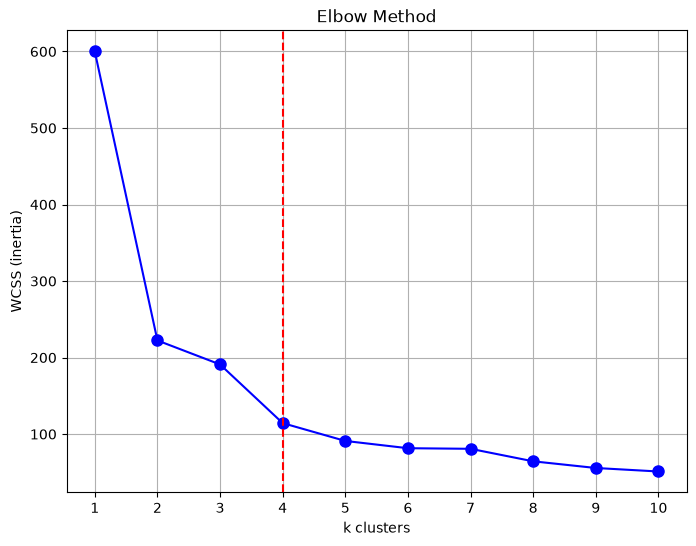

In [8]:
wcss = []
k_values = range(1,11)
for k in k_values:
    kmeans = KMeans(n_clusters=k , init='k-means++', random_state=42)
    kmeans.fit(X_std)
    wcss.append(kmeans.inertia_)

k_scelto=4

plt.figure(figsize=(8, 6))
plt.plot(k_values, wcss, 'o-', color = 'blue', markersize=8)
plt.xlabel("k clusters")
plt.ylabel("WCSS (inertia)")
plt.xticks(k_values)
plt.title("Elbow Method")
plt.grid(True)

plt.axvline(x=k_scelto, color='red', linestyle='--', label=f'K ottimale = {k_scelto}',)


plt.show()


## Applicazione Finale & Visualizzazione

Silhouette Score per K=3: 0.4799


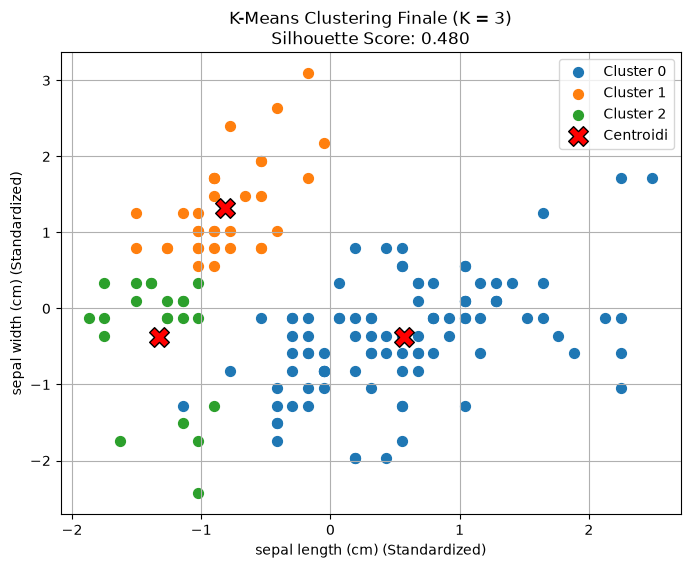

In [17]:
k_finale = 3  
kmeans_final = KMeans(n_clusters=k_finale, init='k-means++', random_state=42)
cluster_labels = kmeans_final.fit_predict(X_std)


sil_score = silhouette_score(X_std, cluster_labels)
print(f'Silhouette Score per K={k_finale}: {sil_score:.4f}')


plt.figure(figsize=(8, 6))
for k in range(k_finale):
  plt.scatter(X_std[cluster_labels == k, 0], X_std[cluster_labels == k, 1], label=f'Cluster {k}',s=50)

centroids = kmeans_final.cluster_centers_
plt.scatter( centroids[:, 0],centroids[:, 1], s=200, c='red', marker='X', edgecolor='black', label='Centroidi')
plt.xlabel(f'{feature_names[0]} (Standardized)')
plt.ylabel(f'{feature_names[1]} (Standardized)')
plt.title(
    f'K-Means Clustering Finale (K = {k_finale})\nSilhouette Score:'
    f' {sil_score:.3f}'
)
plt.legend()
plt.grid(True)
plt.show()